# Manual funder evaluation

Run top to bottom from the repository root or `evals/`. This notebook reads the three annotation CSVs and leaves them unchanged. It reproduces the performance estimates, paired database differences, and count agreement using **Krippendorff’s interval alpha** and **Gwet’s AC2 with linear weights**. It requires NumPy, pandas, and Matplotlib. The 500 articles are the existing sample; bootstrap resampling estimates uncertainty and does not recreate the original WoS sampling step.

A rating records declared funders $T$, correct matches $C$, and wrong matches $W$. Available annotators are weighted equally within each paper, then papers equally. Ratios with zero denominators stay missing. Jacob’s blank wrong count becomes zero only when $T$ and $C$ are present. Conflicting declared totals and $C>T$ are excluded only from metrics they affect.

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('evals') if Path('evals/records_jacob_20261002.csv').exists() else Path('.')
FILES = {'Jacob': 'records_jacob_20261002.csv', 'Filipi': 'records_filipi_20261002.csv',
         'Jin': 'annotation_ja_20261002.csv'}
SOURCES = ('wos', 'openalex', 'dimensions')
SEED, B = 20261002, 10_000

def ratio(a, b):
    a, b = np.broadcast_arrays(np.asarray(a, float), np.asarray(b, float))
    return np.divide(a, b, out=np.full(a.shape, np.nan), where=b != 0)

def available_mean(x, axis):
    return ratio(np.nansum(x, axis=axis), np.isfinite(x).sum(axis=axis))

def summary(samples):
    finite = np.asarray(samples)[np.isfinite(samples)]
    return np.quantile(finite, [.025, .975]), np.std(finite, ddof=1)

## Read and audit the annotations

Rows are joined by `record_id`, regardless of their order in a CSV. The audit shows incomplete annotations and invalid counts; it does not infer corrections.

In [26]:
tables = {}
for annotator, filename in FILES.items():
    table = pd.read_csv(DATA / filename, dtype=str, keep_default_na=False,
                        encoding='utf-8-sig')
    table['record_id'] = table['record_id'].str.strip()
    if table['record_id'].eq('').any() or table['record_id'].duplicated().any():
        raise ValueError(f'{filename}: empty or duplicate record_id')
    tables[annotator] = table.set_index('record_id')
ids = sorted(set().union(*(set(t.index) for t in tables.values())))
# Axes: paper × annotator × source × (T, C, W).
raw = np.full((len(ids), 3, 3, 3), np.nan)
for ai, (annotator, table) in enumerate(tables.items()):
    table = table.reindex(ids)
    for si, source in enumerate(SOURCES):
        for fi, field in enumerate(('declared_funder_count', 'correct_match_count',
                                    'wrong_match_count')):
            raw[:, ai, si, fi] = pd.to_numeric(
                table[f'{source}_{field}'].replace('', np.nan),
                errors='raise').to_numpy(dtype=float)
    if annotator == 'Jacob':
        blank_wrong = np.isnan(raw[:, ai, :, 2]) & np.isfinite(raw[:, ai, :, :2]).all(axis=-1)
        raw[:, ai, :, 2][blank_wrong] = 0
T, C, W = (raw[..., i].copy() for i in range(3))
conflict = np.zeros((len(ids), 3), dtype=bool)
for pi in range(len(ids)):
    for ai in range(3):
        observed = T[pi, ai, np.isfinite(T[pi, ai])]
        conflict[pi, ai] = len(set(observed)) > 1
impossible = np.isfinite(C) & np.isfinite(T) & (C > T)
partial = (np.isfinite(raw).sum(axis=-1) > 0) & (np.isfinite(raw).sum(axis=-1) < 3)
coverage = pd.DataFrame([
    {'annotator': name, 'source': source,
     'complete ratings': int(np.isfinite(raw[:, ai, si]).all(axis=1).sum()),
     'no counts': int((~np.isfinite(raw[:, ai, si]).any(axis=1)).sum())}
    for ai, name in enumerate(FILES) for si, source in enumerate(SOURCES)])
audit = pd.Series({'papers': len(ids), 'partial source ratings': int(partial.sum()),
                   'paper–annotator total conflicts': int(conflict.sum()),
                   'correct counts exceeding total': int(impossible.sum())})
print(audit.to_string())
display(coverage)

papers                             500
partial source ratings               5
paper–annotator total conflicts      6
correct counts exceeding total       1


,annotator,source,complete ratings,no counts
0,Jacob,wos,500,0
1,Jacob,openalex,499,1
2,Jacob,dimensions,500,0
3,Filipi,wos,479,21
4,Filipi,openalex,479,21
5,Filipi,dimensions,479,20
6,Jin,wos,489,11
7,Jin,openalex,488,11
8,Jin,dimensions,486,11


## Performance estimates and paper sampling

Per rating: recall $C/T$, precision $C/(C+W)$, original error $W/T$, hit $1[C>0]$, all-hits $1[C=T]$ for $T>0$, and any-wrong $1[W>0]$. All-hits retains its complete-recall meaning even when extra wrong funders exist. Pooled ratios sum paper-level mean counts over eligible ratings. Each bootstrap draw samples article IDs with replacement and keeps all sources and annotators attached to each article.

In [27]:
T[conflict[:, :, None].repeat(3, axis=2)] = np.nan
C[impossible] = np.nan
ratings = {}
ratings['recall'] = np.where(T > 0, ratio(C, T), np.nan)
ratings['precision'] = np.where((C + W) > 0, ratio(C, C + W), np.nan)
ratings['original error'] = np.where(T > 0, ratio(W, T), np.nan)
ratings['hit'] = np.where(np.isfinite(C), (C > 0).astype(float), np.nan)
ratings['all-hits'] = np.where((T > 0) & np.isfinite(C), (C == T).astype(float), np.nan)
ratings['any wrong'] = np.where(np.isfinite(W), (W > 0).astype(float), np.nan)
pooled = {'pooled recall': (C, T), 'pooled precision': (C, C + W),
          'pooled original error': (W, T)}
boot = np.random.default_rng(SEED).integers(0, len(ids), size=(B, len(ids)))
rows = []
for source_i, source in enumerate(SOURCES):
    for metric, values in ratings.items():
        per_paper = available_mean(values[:, :, source_i], axis=1)
        samples = available_mean(per_paper[boot], axis=1)
        ci, se = summary(samples)
        rows.append((metric, source, int(np.isfinite(per_paper).sum()),
                     float(available_mean(per_paper, axis=0)), se, *ci))
    for metric, (numerator, denominator) in pooled.items():
        valid = np.isfinite(numerator[:, :, source_i]) & np.isfinite(denominator[:, :, source_i])
        a = available_mean(np.where(valid, numerator[:, :, source_i], np.nan), axis=1)
        b = available_mean(np.where(valid, denominator[:, :, source_i], np.nan), axis=1)
        samples = ratio(np.nansum(a[boot], axis=1), np.nansum(b[boot], axis=1))
        ci, se = summary(samples)
        rows.append((metric, source, int(valid.any(axis=1).sum()),
                     float(ratio(np.nansum(a), np.nansum(b))), se, *ci))
performance = pd.DataFrame(rows, columns=['metric', 'source', 'n papers',
                                           'estimate', 'SE', 'CI low', 'CI high'])
display(performance.round(3))

,metric,source,n papers,estimate,SE,CI low,CI high
0,recall,wos,494,0.654,0.017,0.622,0.686
1,precision,wos,432,0.891,0.011,0.869,0.911
2,original error,wos,494,0.073,0.008,0.058,0.088
3,hit,wos,500,0.795,0.017,0.762,0.828
4,all-hits,wos,494,0.466,0.021,0.424,0.508
5,any wrong,wos,500,0.150,0.013,0.125,0.175
6,pooled recall,wos,499,0.637,0.015,0.607,0.667
7,pooled precision,wos,500,0.904,0.008,0.888,0.920
8,pooled original error,wos,499,0.067,0.006,0.055,0.078
9,recall,openalex,494,0.459,0.019,0.421,0.497


## Paired database differences

For every pair, keep only ratings eligible for **both** sources. Average the rating differences within papers, then average papers. For pooled ratios, recompute each ratio from summed, matched paper-level mean counts. The plotted intervals are **pointwise** 95% bootstrap CIs

In [28]:
pairs = ((0, 1), (0, 2), (1, 2))
rows = []
for a, b in pairs:
    for metric, values in ratings.items():
        valid = np.isfinite(values[:, :, a]) & np.isfinite(values[:, :, b])
        paper_difference = available_mean(np.where(valid, values[:, :, a]-values[:, :, b], np.nan), axis=1)
        samples = available_mean(paper_difference[boot], axis=1)
        ci, _ = summary(samples)
        rows.append((metric, SOURCES[a], SOURCES[b], int(valid.any(axis=1).sum()),
                     float(available_mean(paper_difference, axis=0)), *ci))
    for metric, (numerator, denominator) in pooled.items():
        valid = np.isfinite(numerator[:, :, a]) & np.isfinite(denominator[:, :, a]) & \
                np.isfinite(numerator[:, :, b]) & np.isfinite(denominator[:, :, b])
        def matched_paper_counts(source_i):
            return (available_mean(np.where(valid, x[:, :, source_i], np.nan), axis=1)
                    for x in (numerator, denominator))
        an, ad = matched_paper_counts(a)
        bn, bd = matched_paper_counts(b)
        estimate = ratio(np.nansum(an), np.nansum(ad)) - ratio(np.nansum(bn), np.nansum(bd))
        samples = ratio(np.nansum(an[boot], axis=1), np.nansum(ad[boot], axis=1)) - \
                  ratio(np.nansum(bn[boot], axis=1), np.nansum(bd[boot], axis=1))
        ci, _ = summary(samples)
        rows.append((metric, SOURCES[a], SOURCES[b], int(valid.any(axis=1).sum()),
                     float(estimate), *ci))
differences = pd.DataFrame(rows, columns=['metric', 'first', 'second', 'n papers',
                                           'difference', 'CI low', 'CI high'])
display(differences.round(3))

,metric,first,second,n papers,difference,CI low,CI high
0,recall,wos,openalex,494,0.195,0.152,0.240
1,precision,wos,openalex,280,0.044,0.012,0.076
2,original error,wos,openalex,494,-0.094,-0.180,-0.036
3,hit,wos,openalex,500,0.228,0.184,0.275
4,all-hits,wos,openalex,494,0.134,0.088,0.180
5,any wrong,wos,openalex,500,-0.021,-0.056,0.013
6,pooled recall,wos,openalex,499,0.184,0.134,0.232
7,pooled precision,wos,openalex,500,0.106,0.058,0.165
8,pooled original error,wos,openalex,499,-0.048,-0.094,-0.015
9,recall,wos,dimensions,494,0.116,0.079,0.155


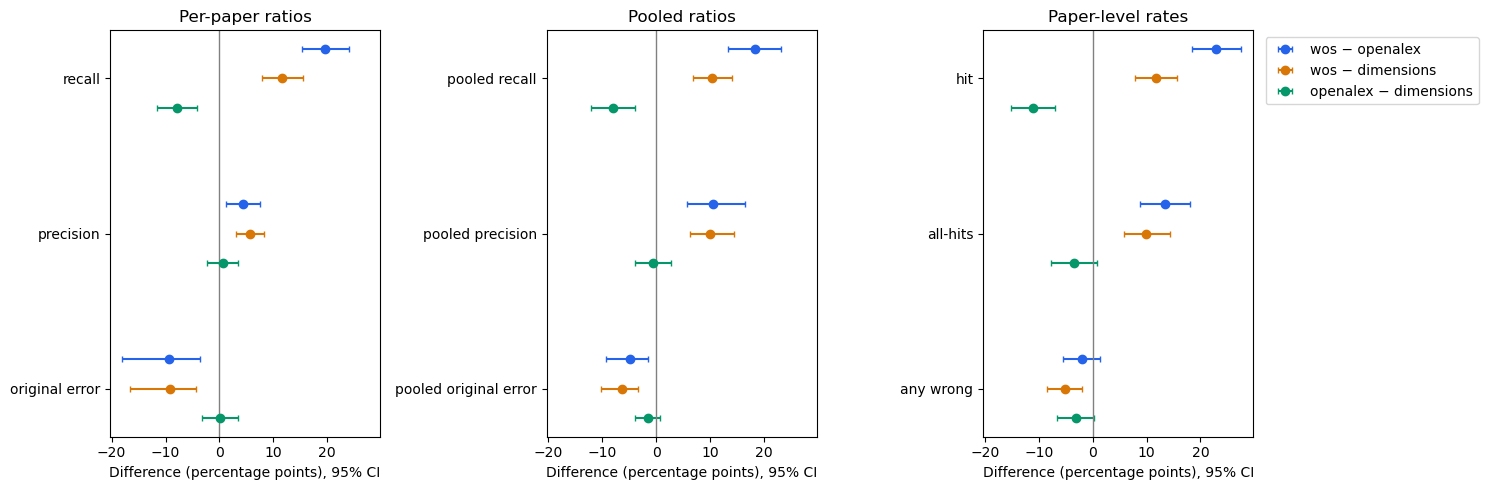

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)
groups = [('Per-paper ratios', ['recall', 'precision', 'original error']),
          ('Pooled ratios', ['pooled recall', 'pooled precision', 'pooled original error']),
          ('Paper-level rates', ['hit', 'all-hits', 'any wrong'])]
colors = ['#2563eb', '#d97706', '#059669']
for ax, (title, names) in zip(axes, groups):
    part = differences.set_index(['metric', 'first', 'second'])
    for j, (a, b) in enumerate(pairs):
        y = np.arange(len(names)) + (j-1)*0.19
        sub = part.loc[[(m, SOURCES[a], SOURCES[b]) for m in names]]
        center = 100 * sub['difference'].to_numpy()
        low, high = 100 * sub['CI low'].to_numpy(), 100 * sub['CI high'].to_numpy()
        ax.errorbar(center, y, xerr=[center-low, high-center], fmt='o', capsize=2,
                    color=colors[j], label=f'{SOURCES[a]} − {SOURCES[b]}')
    ax.axvline(0, color='0.5', linewidth=1)
    ax.set_yticks(np.arange(len(names)), names)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('Difference (percentage points), 95% CI')
axes[2].legend(loc='upper left', bbox_to_anchor=(1.02, 1))
fig.tight_layout()
plt.show()

## Inter-annotator agreement on counts

The declared count is evaluated once per paper and annotator. Correct and wrong counts are evaluated separately for each database. Both measures use papers with at least two eligible ratings. **Interval alpha** uses squared count differences and standard coincidence weighting, under which papers with three ratings contribute more than papers with two. **AC2** uses linear weights $1-|a-b|/K$ over the full integer domain $0,\ldots,K$, where $K$ is the largest valid count among pairable papers for that field. AC2 averages paper agreements equally. Both use the same article-level bootstrap for intervals; AC2 keeps its full-data $K$ fixed in resamples.

In [30]:
def interval_parts(values):
    n = np.isfinite(values).sum(axis=1)
    total, squares = np.nansum(values, axis=1), np.nansum(values**2, axis=1)
    observed = ratio(2*(n*squares-total**2), n-1)
    return np.where((n >= 2)[:, None], np.column_stack((n, total, squares, observed)), 0)

def interval_alpha(parts, axis=0):
    n, total, squares, observed = np.moveaxis(parts.sum(axis=axis), -1, 0)
    expected = ratio(2*(n*squares-total**2), n-1)
    return 1 - ratio(observed, expected)

def ac2_parts(values, K):
    n = np.isfinite(values).sum(axis=1)
    observed = np.full(len(values), np.nan)
    proportions = np.full((len(values), K+1), np.nan)
    for i in np.flatnonzero(n >= 2):
        v = values[i, np.isfinite(values[i])].astype(int)
        proportions[i] = np.bincount(v, minlength=K+1) / len(v)
        if K:
            observed[i] = np.mean([1 - abs(a-b)/K
                                   for j, a in enumerate(v) for b in v[j+1:]])
    return observed, proportions

def ac2(observed, proportions, K, axis=0):
    if not K:
        return np.nan
    p = available_mean(proportions, axis=axis)
    pa = available_mean(observed, axis=axis)
    labels = np.arange(K+1)
    weight_sum = np.sum(1 - abs(labels[:, None]-labels[None, :])/K)
    pe = weight_sum*np.sum(p*(1-p), axis=-1)/((K+1)*K)
    return ratio(pa-pe, 1-pe)

# Keep independently valid wrong counts and drop impossible correct counts.
count_arrays = [('paper', 'declared', np.full((len(ids), 3), np.nan))]
for ai in range(3):
    for pi in range(len(ids)):
        valid_total = T[pi, ai, np.isfinite(T[pi, ai])]
        if len(valid_total): count_arrays[0][2][pi, ai] = valid_total[0]
for si, source in enumerate(SOURCES):
    count_arrays += [(source, 'correct', C[:, :, si]),
                     (source, 'wrong', W[:, :, si])]
rows = []
for source, field, values in count_arrays:
    eligible = np.isfinite(values).sum(axis=1) >= 2
    parts = interval_parts(values)
    alpha_draws = interval_alpha(parts[boot], axis=1)
    alpha_ci, _ = summary(alpha_draws)
    K = int(np.nanmax(values[eligible]))
    obs, prop = ac2_parts(values, K)
    ac2_draws = []
    for batch in np.array_split(boot, 40):
        ac2_draws.extend(ac2(obs[batch], prop[batch], K, axis=1))
    ac2_ci, _ = summary(ac2_draws)
    rows.append((source, field, int(eligible.sum()), K,
                 float(interval_alpha(parts)), *alpha_ci,
                 float(ac2(obs, prop, K)), *ac2_ci))
agreement = pd.DataFrame(rows, columns=['source', 'count', 'n papers', 'K',
                                        'interval alpha', 'alpha CI low', 'alpha CI high',
                                        'linear AC2', 'AC2 CI low', 'AC2 CI high'])
display(agreement.round(3))

,source,count,n papers,K,interval alpha,alpha CI low,alpha CI high,linear AC2,AC2 CI low,AC2 CI high
0,paper,declared,493,15,0.824,0.776,0.861,0.923,0.912,0.933
1,wos,correct,493,13,0.839,0.797,0.872,0.939,0.929,0.948
2,wos,wrong,493,3,0.439,0.332,0.544,0.932,0.917,0.945
3,openalex,correct,493,9,0.856,0.825,0.883,0.935,0.922,0.946
4,openalex,wrong,493,22,0.901,0.577,0.963,0.990,0.988,0.992
5,dimensions,correct,493,13,0.793,0.747,0.831,0.930,0.920,0.940
6,dimensions,wrong,492,19,0.763,0.349,0.906,0.981,0.977,0.984


## Disagreement on wrong counts

Compare Jacob and Filipi on the **same eligible papers** for each database. The table shows the percentage of papers with any wrong funder and the mean and pooled wrong/declared ratios. 


In [31]:
jacob, filipi = [list(FILES).index(name) for name in ('Jacob', 'Filipi')]
paired_rows = []
for si, source in enumerate(SOURCES):
    binary = ratings['any wrong'][:, [jacob, filipi], si]
    old = ratings['original error'][:, [jacob, filipi], si]
    matched_binary = np.isfinite(binary).all(axis=1)
    matched_old = np.isfinite(old).all(axis=1)
    paired_T, paired_W = T[:, [jacob, filipi], si], W[:, [jacob, filipi], si]
    matched_pooled = np.isfinite(paired_T).all(axis=1) & np.isfinite(paired_W).all(axis=1)
    paired_rows.append({
        'source': source, 'n any wrong': int(matched_binary.sum()),
        'Jacob any wrong': binary[matched_binary, 0].mean(),
        'Filipi any wrong': binary[matched_binary, 1].mean(),
        'n mean error': int(matched_old.sum()),
        'Jacob mean error': old[matched_old, 0].mean(),
        'Filipi mean error': old[matched_old, 1].mean(),
        'n pooled error': int(matched_pooled.sum()),
        'Jacob pooled error': float(ratio(paired_W[matched_pooled, 0].sum(),
                                          paired_T[matched_pooled, 0].sum())),
        'Filipi pooled error': float(ratio(paired_W[matched_pooled, 1].sum(),
                                           paired_T[matched_pooled, 1].sum()))})
paired_interpretations = pd.DataFrame(paired_rows)
shown = paired_interpretations.copy()
for column in shown.columns:
    if column.startswith(('Jacob ', 'Filipi ')):
        shown[column] = shown[column].map(lambda value: f'{value:.1%}')
display(shown)



,source,n any wrong,Jacob any wrong,Filipi any wrong,n mean error,Jacob mean error,Filipi mean error,n pooled error,Jacob pooled error,Filipi pooled error
0,wos,479,7.7%,24.2%,467,3.9%,11.7%,479,3.6%,10.2%
1,openalex,478,10.5%,24.1%,466,13.2%,21.0%,478,8.4%,15.6%
2,dimensions,480,10.4%,32.7%,467,10.4%,25.1%,480,7.1%,20.6%


## General exact count agreement

For declared, correct, and wrong counts, use papers with at least two eligible annotators. Average pairwise exact agreement and absolute count differences within each paper, then average papers equally.


In [32]:
count_rows = []
for source, field, values in count_arrays:
    paper_differences = []
    for paper in values:
        observed = paper[np.isfinite(paper)]
        if len(observed) >= 2:
            distances = abs(observed[:, None] - observed[None, :])
            paper_differences.append(distances[np.triu_indices(len(observed), 1)])
    count_rows.append({'source': source, 'count': field, 'n papers': len(paper_differences),
                       'exact agreement': np.mean([np.mean(d == 0) for d in paper_differences]),
                       'mean absolute difference': np.mean([np.mean(d) for d in paper_differences])})
count_discrepancies = pd.DataFrame(count_rows)
shown = count_discrepancies.copy()
shown['exact agreement'] = shown['exact agreement'].map(lambda value: f'{value:.1%}')
shown['mean absolute difference'] = shown['mean absolute difference'].map(lambda value: f'{value:.2f}')
display(shown)


,source,count,n papers,exact agreement,mean absolute difference
0,paper,declared,493,64.4%,0.54
1,wos,correct,493,71.6%,0.39
2,wos,wrong,493,85.3%,0.16
3,openalex,correct,493,78.7%,0.29
4,openalex,wrong,493,85.7%,0.18
5,dimensions,correct,493,68.9%,0.44
6,dimensions,wrong,492,79.8%,0.28


The alpha and AC2 coefficients describe agreement on **numbers of funders**. They do not establish agreement on individual funder identities. Missing annotations are not negative judgments. The resulting estimates and intervals are conditional on these annotators and on the papers with eligible ratings.